# 06 — Interpreting the satellites: where their energy comes from

The plasmon satellite of the G0W spectral function is the one-plasmon emission edge of $-\mathrm{Im}\,\Sigma$.
To one-plasmon order

$$-\mathrm{Im}\,\Sigma_{\mathbf{k}}(\varepsilon)\simeq\pi\sum_{\mathbf{q}}w_{\mathbf{q}}F(\mathbf{k},\mathbf{k}-\mathbf{q})R(\mathbf{q})\,
\delta\big(\varepsilon-E_{\mathbf{k}}(\mathbf{q})\big),\qquad E_{\mathbf{k}}(\mathbf{q})=\xi_{\mathbf{k}-\mathbf{q}}+\omega_{\rm pl}(\mathbf{q}),$$

a density of final states (electron at $\mathbf{k}-\mathbf{q}$ plus a plasmon $\mathbf{q}$). It peaks where $E_{\mathbf{k}}(\mathbf{q})$
is stationary, so the satellite energy is a stationary value of $E_{\mathbf{k}}(\mathbf{q})$, not $\omega_{\rm pl}$ at one $\mathbf{q}$
(the full calculation integrates the complete spectral density; the pole form is only for interpretation).

* **Dispersive plasmon (graphene):** $\varepsilon_{\rm sat}\simeq\xi_{\mathbf{k}}+\Delta$, $\Delta=\max_q[\omega_{\rm pl}(q)-\hbar v_Fq]$,
  reached where $d\omega_{\rm pl}/dq=v_F$.
* **Flat plasmon and flat bands (TBG):** $\varepsilon_{\rm sat}\simeq\xi_{\rm VH}+\bar\omega_{\rm pl}$.

This notebook checks both estimates against the full calculation and decomposes $-\mathrm{Im}\,\Sigma$ at the
satellite into the energy carried by the plasmon and the energy of the final electron. Notes: Sec. 9.

In [1]:
import sys, time
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")
from g0w.models import slg_stack as ss, slg_self_energy as se
from g0w import self_energy_ppa as ppa, satellites as sat
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

cfgs = {"both doped": ss.SLGStackConfig(n_sample=0.01, n_tip=0.01, chi_on_tip=True, d_hbn=1.0, eta=1e-3),
        "tip inert": ss.SLGStackConfig(n_sample=0.01, n_tip=0.01, chi_on_tip=False, d_hbn=1.0, eta=1e-3)}
c0 = cfgs["both doped"]
alpha_g = 1.4399764 / (np.sqrt(6.41 * 3.0) * c0.hv)
print(f"k_F = {c0.k_F:.4f} nm^-1, E_F = {c0.E_F*1e3:.1f} meV, alpha_g = {alpha_g:.3f}")

k_F = 0.1772 nm^-1, E_F = 116.6 meV, alpha_g = 0.499


## 1. Graphene: the emission edge from the plasmon dispersion

For a given $q$ the lowest final energy is obtained by emitting along the electron velocity,
$E(q)=\xi_{\mathbf{k}}-\hbar v_Fq+\omega_{\rm pl}(q)$. For a 2D plasmon $\omega_{\rm pl}-\hbar v_Fq$ first rises and then falls;
at its maximum a range of $q$ contributes at the same energy (a caustic) and $-\mathrm{Im}\,\Sigma$ has its edge.

In [2]:
qf = np.linspace(0.005, 1.2, 200) * c0.k_F
omf = np.linspace(1e-4, 2.8 * c0.E_F, 1000)
edge = {}
for name, c in cfgs.items():
    Wf = se.build_W_grid(c, qf, omf)
    Sf = -np.imag(Wf[:, :, ss.SAMPLE_LAYER, ss.SAMPLE_LAYER]) / np.pi
    wpl = sat.plasmon_branch(qf, omf, Sf, c.hv)
    d = sat.dispersive_edge(qf, wpl, c.hv)
    edge[name] = dict(wpl=wpl, **d)
    print(f"{name:10s}: Delta = max_q[w_pl - hbar v q] = {d['Delta']*1e3:5.1f} meV at q* = {d['q_star']/c.k_F:.2f} k_F "
          f"(w_pl(q*) = {d['omega_star']*1e3:.1f} meV, d w_pl/dq = {d['slope']:.2f} v_F)")
cl = sat.sqrt_plasmon_edge(c0.E_F, c0.k_F, alpha_g)
print(f"closed form for w_pl = sqrt(g e^2 E_F q / 2 eps): Delta = alpha_g E_F / 2 = {cl['Delta']*1e3:.1f} meV, "
      f"q* = alpha_g k_F / 2 = {cl['q_star']/c0.k_F:.2f} k_F")

both doped: Delta = max_q[w_pl - hbar v q] =  53.7 meV at q* = 0.40 k_F (w_pl(q*) = 99.8 meV, d w_pl/dq = 1.02 v_F)
tip inert : Delta = max_q[w_pl - hbar v q] =  34.1 meV at q* = 0.39 k_F (w_pl(q*) = 79.5 meV, d w_pl/dq = 1.01 v_F)
closed form for w_pl = sqrt(g e^2 E_F q / 2 eps): Delta = alpha_g E_F / 2 = 29.1 meV, q* = alpha_g k_F / 2 = 0.25 k_F


## 2. Comparison with the full-frequency calculation

Same grids as notebooks 02 and 04. The edge predicts the peak of $-\mathrm{Im}\,\Sigma$; the satellite peak of $A$ is
shifted further by the Dyson denominator, and its offset from the quasiparticle peak (what a QTM line cut shows)
also contains the downward shift of the quasiparticle by $\mathrm{Re}\,\Sigma$.

In [3]:
q = np.linspace(0.02 * c0.k_F, 3 * c0.k_F, 96); om = np.linspace(1e-4, 2.8 * c0.E_F, 480)
eps = np.linspace(-0.35, 0.35, 1401); qw = ppa.make_radial_q_weights(q)
grids = {}
for name, c in cfgs.items():
    W = se.build_W_grid(c, q, om)
    grids[name] = dict(W=W, S=-np.imag(W[:, :, ss.SAMPLE_LAYER, ss.SAMPLE_LAYER]) / np.pi,
                       ker=se.build_sample_kernel(c, om, W, eps, q, eta_self=1e-3, k_max=3.2 * c.k_F))
rows = []
print(" config      |p|/kF  xi_k  xi_k+Delta  peak(-ImS)  sat(A)   E_qp   sat-E_qp  [meV]")
for name, c in cfgs.items():
    for pk in (1.5, 2.0, 2.5):
        p = np.array([0.0, pk * c.k_F]); xi = se.quasiparticle_energy(c, p, +1)
        Sg = se.sigma_full_frequency_kernel(c, p, eps, q, grids[name]["ker"], qw, band_ext=+1)[0, 0]
        A = (1 / np.pi) * (2e-3 - Sg.imag) / ((eps - xi - Sg.real) ** 2 + (2e-3 - Sg.imag) ** 2)
        e_qp = eps[np.argmax(np.where(np.abs(eps - xi) < 0.05, A, 0))]
        above = eps > e_qp + 0.015
        e_im = eps[above][np.argmax(-Sg.imag[above])]
        loc = np.r_[False, (A[1:-1] > A[:-2]) & (A[1:-1] > A[2:]), False] & above
        e_sat = eps[np.flatnonzero(loc)[np.argmax(A[loc])]]
        pred = xi + edge[name]["Delta"]
        rows.append(dict(name=name, pk=pk, xi=xi, pred=pred, e_im=e_im, e_sat=e_sat, e_qp=e_qp, Sg=Sg))
        print(f" {name:10s}  {pk:4.1f}  {xi*1e3:6.1f}  {pred*1e3:7.1f}    {e_im*1e3:7.1f}   {e_sat*1e3:7.1f}  "
              f"{e_qp*1e3:6.1f}   {(e_sat-e_qp)*1e3:6.1f}")

 config      |p|/kF  xi_k  xi_k+Delta  peak(-ImS)  sat(A)   E_qp   sat-E_qp  [meV]
 both doped   1.5    58.3    112.0      112.5     115.0    42.0     73.0
 both doped   2.0   116.6    170.3      170.5     174.5    95.5     79.0
 both doped   2.5   174.9    228.6      229.0     233.0   151.0     82.0
 tip inert    1.5    58.3     92.4       92.5      95.5    42.0     53.5
 tip inert    2.0   116.6    150.7      151.0     157.5    95.0     62.5
 tip inert    2.5   174.9    209.0      209.0     215.0   150.5     64.5


## 3. Energy budget of the satellite

Decomposing $-\mathrm{Im}\,\Sigma(\mathbf{k},\varepsilon_{\rm sat})$ ($\eta\to0$) into the energy $\omega=\varepsilon-\xi'$ carried away by
the plasmon and the energy $\xi'$ of the final electron shows that neither $\omega_{\rm pl}(q^*)$ nor $\Delta$ is "the" plasmon
energy: the energy is shared between the plasmon and the drop in the electron's own energy.

In [4]:
loss_slg = {}
for r in rows:
    if r["name"] != "both doped" or r["pk"] not in (1.5, 2.0):
        continue
    c = cfgs[r["name"]]; p = np.array([0.0, r["pk"] * c.k_F])
    d = sat.slg_energy_loss(c, p, r["e_im"], q, om, grids[r["name"]]["S"], qw)
    w = sat.weighted_summary(d["omega_lost"], d["weight"]); x = sat.weighted_summary(d["xi_final"], d["weight"])
    qs = sat.weighted_summary(d["q"], d["weight"])
    loss_slg[r["pk"]] = d
    print(f"|p| = {r['pk']} k_F at eps = {r['e_im']*1e3:.1f} meV: -Im Sigma(eta->0) = {w['total']*1e3:.1f} meV; "
          f"plasmon energy mean {w['mean']*1e3:.1f} (IQR {w['q25']*1e3:.1f}-{w['q75']*1e3:.1f}) meV; "
          f"final xi' mean {x['mean']*1e3:.1f} meV; q mean {qs['mean']/c.k_F:.2f} k_F")

|p| = 1.5 k_F at eps = 112.5 meV: -Im Sigma(eta->0) = 57.9 meV; plasmon energy mean 82.1 (IQR 67.3-99.5) meV; final xi' mean 30.4 meV; q mean 0.30 k_F
|p| = 2.0 k_F at eps = 170.5 meV: -Im Sigma(eta->0) = 83.3 meV; plasmon energy mean 95.8 (IQR 77.1-114.5) meV; final xi' mean 74.7 meV; q mean 0.42 k_F


## 4. Twisted bilayer graphene: flat plasmon and flat bands

Both the plasmon and the final states are nearly dispersionless, so the $q$ integral hardly matters and
$\varepsilon_{\rm sat}\simeq\xi_{\rm VH}+\bar\omega_{\rm pl}$, with $\xi_{\rm VH}$ the flat-band van Hove energy.

In [5]:
from g0w.models import tbg_model as tm, tbg_stack as tst, tbg_self_energy as tse
t0 = time.time()
p_t = tm.TBGParams(theta_deg=1.20, uAB=0.117, uAA_ratio=0.7, n_sites=18, n_bands=4)
tbg = tm.build_tbg(p_t, verbose=False); lh = tm.build_layer_helper(tbg, verbose=False)
eta = p_t.eta; om_t = np.linspace(2 * eta, 0.16, 320)
chi = tm.chi0_tbg(lh, om_t + 1j * eta, verbose=False)
cfg_t = tst.TBGSLGConfig(tbg=p_t, d_tip=1.0, n_tip=0.0)
qc = np.asarray(tbg["q_sample"].coords)
_, _, W_t = tst.build_stack_eps_W(cfg_t, qc, om_t, chi, verbose=False)
S_t = tse.sample_spectral_density(W_t); qw_t = tse.q_weights_tbg(tbg)
print(f"TBG pipeline: {time.time()-t0:.1f} s")
TrS = np.real(np.trace(S_t, axis1=2, axis2=3)); nz = np.linalg.norm(qc, axis=1) > 0
wpl_t = om_t[np.argmax(TrS, axis=1)][nz]
print(f"flat-band plasmon (peak of Tr S over the mesh): median {np.median(wpl_t)*1e3:.1f} meV, "
      f"IQR {np.percentile(wpl_t,25)*1e3:.1f}-{np.percentile(wpl_t,75)*1e3:.1f} meV")
E_t = np.asarray(tbg["crystal"].band_structure.energies) - tbg["mu"]
h, b = np.histogram(E_t[4], bins=60, range=(0, 0.03)); xi_vh = 0.5 * (b[np.argmax(h)] + b[np.argmax(h) + 1])
print(f"conduction flat-band van Hove energy (DOS peak): {xi_vh*1e3:.1f} meV -> estimate xi_VH + w_pl = "
      f"{(xi_vh + np.median(wpl_t))*1e3:.1f} meV")
ki = int(tm.path_indices(tbg, ("K", "Gamma", "M", "K"))["indices"][0])      # kappa_top
eg = np.linspace(0.02, 0.07, 101)
imS_t = np.array([sat.minus_im_sigma_from_loss(sat.tbg_energy_loss(tbg, lh, S_t, om_t, qw_t, ki, 4, e)) for e in eg])
e_pk = eg[np.argmax(imS_t)]
d_t = sat.tbg_energy_loss(tbg, lh, S_t, om_t, qw_t, ki, 4, e_pk)
w_t = sat.weighted_summary(d_t["omega_lost"], d_t["weight"]); x_t = sat.weighted_summary(d_t["xi_final"], d_t["weight"])
flat = np.isin(d_t["final_band"], (3, 4))
print(f"-Im Sigma of the flat conduction band at kappa_top peaks at {e_pk*1e3:.1f} meV (eta -> 0): "
      f"plasmon energy mean {w_t['mean']*1e3:.1f} (IQR {w_t['q25']*1e3:.1f}-{w_t['q75']*1e3:.1f}) meV, "
      f"final xi' mean {x_t['mean']*1e3:.1f} meV, flat-band share of the final states {d_t['weight'][flat].sum()/w_t['total']:.2f}")

TBG pipeline: 108.8 s
flat-band plasmon (peak of Tr S over the mesh): median 34.2 meV, IQR 32.7-35.2 meV
conduction flat-band van Hove energy (DOS peak): 6.2 meV -> estimate xi_VH + w_pl = 40.5 meV
-Im Sigma of the flat conduction band at kappa_top peaks at 41.5 meV (eta -> 0): plasmon energy mean 34.8 (IQR 33.8-35.6) meV, final xi' mean 6.7 meV, flat-band share of the final states 1.00


## 5. Summary figure (notes, Fig. "satellites")

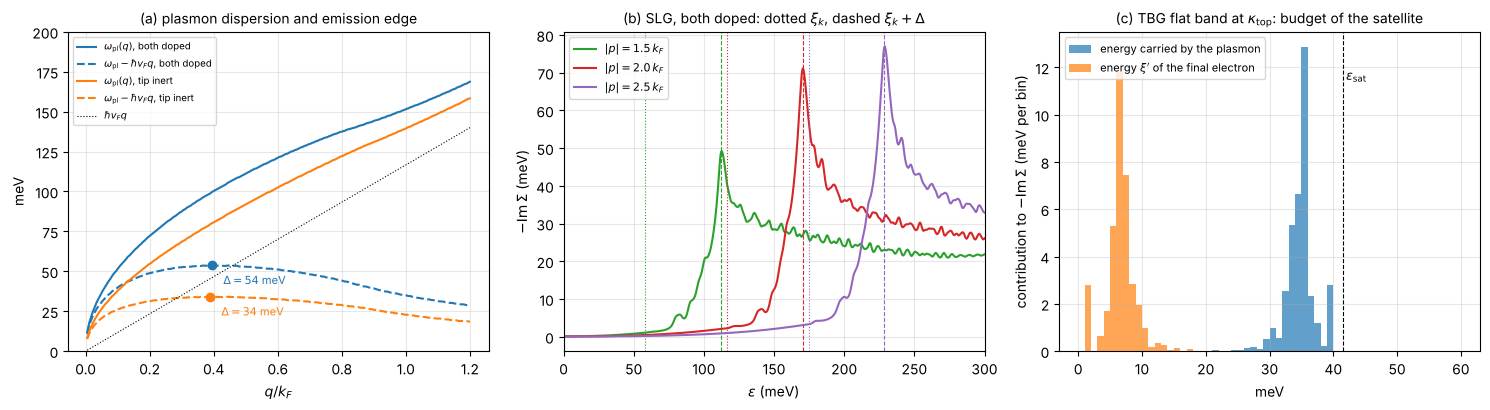

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for (name, e), col in zip(edge.items(), ("C0", "C1")):
    ax[0].plot(qf / c0.k_F, e["wpl"] * 1e3, color=col, label=rf"$\omega_{{\rm pl}}(q)$, {name}")
    ax[0].plot(qf / c0.k_F, (e["wpl"] - c0.hv * qf) * 1e3, "--", color=col, label=rf"$\omega_{{\rm pl}}-\hbar v_Fq$, {name}")
    ax[0].plot(e["q_star"] / c0.k_F, e["Delta"] * 1e3, "o", color=col)
    ax[0].annotate(rf"$\Delta={e['Delta']*1e3:.0f}$ meV", (e["q_star"] / c0.k_F, e["Delta"] * 1e3),
                   textcoords="offset points", xytext=(8, -14), fontsize=8, color=col)
ax[0].plot(qf / c0.k_F, c0.hv * qf * 1e3, "k:", lw=0.8, label=r"$\hbar v_Fq$")
ax[0].set_xlabel(r"$q/k_F$"); ax[0].set_ylabel("meV"); ax[0].set_ylim(0, 200); ax[0].legend(fontsize=7)
ax[0].set_title("(a) plasmon dispersion and emission edge", fontsize=10)
for r, col in zip([r for r in rows if r["name"] == "both doped"], ("C2", "C3", "C4")):
    ax[1].plot(eps * 1e3, -r["Sg"].imag * 1e3, color=col, label=rf"$|p|={r['pk']}\,k_F$")
    ax[1].axvline(r["xi"] * 1e3, color=col, ls=":", lw=0.8); ax[1].axvline(r["pred"] * 1e3, color=col, ls="--", lw=0.8)
ax[1].set_xlim(0, 300); ax[1].set_xlabel(r"$\varepsilon$ (meV)"); ax[1].set_ylabel(r"$-\mathrm{Im}\,\Sigma$ (meV)")
ax[1].legend(fontsize=8); ax[1].set_title(r"(b) SLG, both doped: dotted $\xi_k$, dashed $\xi_k+\Delta$", fontsize=10)
bins = np.linspace(0, 0.06, 61)
ax[2].hist(d_t["omega_lost"] * 1e3, bins=bins * 1e3, weights=d_t["weight"] * 1e3, alpha=0.7, label="energy carried by the plasmon")
ax[2].hist(d_t["xi_final"] * 1e3, bins=bins * 1e3, weights=d_t["weight"] * 1e3, alpha=0.7, label=r"energy $\xi'$ of the final electron")
ax[2].axvline(e_pk * 1e3, color="k", ls="--", lw=0.8); ax[2].text(e_pk * 1e3 + 0.5, ax[2].get_ylim()[1] * 0.85, r"$\varepsilon_{\rm sat}$", fontsize=9)
ax[2].set_xlabel("meV"); ax[2].set_ylabel(r"contribution to $-\mathrm{Im}\,\Sigma$ (meV per bin)")
ax[2].legend(fontsize=8); ax[2].set_title(r"(c) TBG flat band at $\kappa_{\rm top}$: budget of the satellite", fontsize=10)
plt.tight_layout()
fig.savefig(ROOT / "docs" / "figures" / "fig_satellites.png", dpi=110, bbox_inches="tight")
plt.show()